# TP2 — Retrieval-Augmented Generation (Part 1)
## From Documents to a Searchable Knowledge Base

**Module 2IAiasd 9.7 — Agentic AI · IMT Mines Alès**  
**Duration:** 2 h  
**Prerequisites:** TP1 completed (ReAct agent with `bind_tools`)

---

### What you will build today

By the end of this session your internship report will be **searchable by meaning**, not just by keyword.  
You will have:

1. Loaded and inspected your PDF with `PyPDFLoader`
2. Split it into chunks using two different strategies
3. Embedded every chunk with `nomic-embed-text` via Ollama
4. Stored and persisted the vectors in a **ChromaDB** collection
5. Run your first semantic retriever and compared chunking strategies

### The bigger picture

```
  Your PDF
     │
     ▼
  [Load]  ──►  pages (list of Document objects)
     │
     ▼
  [Chunk]  ──►  smaller pieces  (recursive  |  semantic)
     │
     ▼
  [Embed]  ──►  vectors  (nomic-embed-text via Ollama)
     │
     ▼
  [Index]  ──►  ChromaDB  (persisted on disk)
     │
     ▼
  [Retrieve]  ──►  top-k chunks for a query
```

Part 2 (Thursday) adds the LLM on top to answer questions and evaluates the full pipeline with RAGAS.

---

> **Your document:** Use your **2A internship report** (PDF).  
> Place it in the same folder as this notebook and update `PDF_PATH` in Section 1.  
> A fallback sample text is provided in case you do not have your PDF available today.

## Setup — Install dependencies

Run this cell once. It installs everything needed for Parts 1 and 2.

In [3]:
%pip install -q langchain langchain-ollama langchain-community langchain-chroma pypdf chromadb sentence-transformers rank-bm25 langchain-experimental langchain-text-splitters

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
# Pull the embedding model if not already present (~270 MB, run once)
!ollama pull nomic-embed-text
print("✅ nomic-embed-text ready")

✅ nomic-embed-text ready


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest 
pulling 970aa74c0a90: 100% ▕██████████████████▏ 274 MB                         
pulling c71d239df917: 100% ▕██████████████████▏  11 KB                         
pulling ce4a164fc046: 100% ▕██████████████████▏   17 B                         
pulling 31df23ea7daa: 100% ▕██████████████████▏  420 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling 970aa74c0a90: 100% ▕██████████████████▏ 274 MB                         
pulling c71d239df917: 100% ▕██████████████████▏  11 KB                         
pulling ce4a164fc046: 100% ▕██████████████████▏   17 B                         
pulling 31df23ea7daa: 100% ▕██████████████████▏  420 B                         
verifying sha256 digest 
writing manifest 
removing unused layers 
success 


## Imports

In [5]:
import os
import textwrap
from pathlib import Path

# LangChain — document loaders
from langchain_community.document_loaders import PyPDFLoader

# LangChain — text splitters
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_experimental.text_splitter import SemanticChunker

# LangChain — embeddings
from langchain_ollama import OllamaEmbeddings

# LangChain — vector store
from langchain_chroma import Chroma

# Utilities
import numpy as np

print("✅ Imports OK")

C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_26000\1905677204.py:6: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
C:\Users\ThinkPad\AppData\Local\Temp\ipykernel_26000\1905677204.py:10: DeprecationWarning: `langchain-experimental` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-experimental/issues/87 for details.
  from langchain_experimental.text_splitter import SemanticChunker


✅ Imports OK


---
## Section 1 — Load your PDF

### 1.1 Configuration

In [6]:
# ── CONFIGURE THIS ────────────────────────────────────────────────────────────
PDF_PATH = "rapport_stage_Aaidoun_idriss.pdf"   # ← replace with the filename of your report
CHROMA_DIR = "./chroma_db"          # ChromaDB will persist here
EMBED_MODEL = "nomic-embed-text"    # Ollama embedding model
# ─────────────────────────────────────────────────────────────────────────────

# Check the file exists — fall back to sample text if not
if Path(PDF_PATH).exists():
    print(f"✅ Found: {PDF_PATH}")
    USE_SAMPLE = False
else:
    print(f"⚠️  '{PDF_PATH}' not found — using built-in sample text instead.")
    print("   Place your PDF next to this notebook and re-run to use your own document.")
    USE_SAMPLE = True

✅ Found: rapport_stage_Aaidoun_idriss.pdf


### 1.2 Load pages with PyPDFLoader

`PyPDFLoader` reads a PDF and returns one `Document` object per page.  
Each `Document` has two attributes:
- `page_content` — the extracted text
- `metadata` — a dict with at minimum `{"source": "...", "page": N}`

In [7]:
if not USE_SAMPLE:
    loader = PyPDFLoader(PDF_PATH)
    pages = loader.load()
    print(f"📄 Loaded {len(pages)} pages from '{PDF_PATH}'")
else:
    # ── Fallback: build synthetic Document objects from plain text ────────────
    from langchain_core.documents import Document

    SAMPLE_TEXT = """
    Chapter 1 — Introduction to Machine Learning
    Machine learning is a subfield of artificial intelligence that enables computers
    to learn from data without being explicitly programmed. The main paradigms are
    supervised learning, unsupervised learning, and reinforcement learning.
    Supervised learning uses labelled examples. Unsupervised learning finds structure
    in unlabelled data. Reinforcement learning trains agents through reward signals.

    Chapter 2 — Neural Networks
    A neural network is composed of layers of interconnected nodes called neurons.
    Deep learning refers to neural networks with many hidden layers. Backpropagation
    computes gradients used to update weights during training. Activation functions
    such as ReLU and softmax introduce non-linearity into the network.

    Chapter 3 — Large Language Models
    Large Language Models (LLMs) are neural networks trained on massive text corpora
    using the Transformer architecture. They are pre-trained with a next-token
    prediction objective and then fine-tuned for specific tasks. Examples include
    GPT-4, Llama, Mistral, and Qwen. Ollama allows running LLMs locally.

    Chapter 4 — Retrieval-Augmented Generation
    RAG combines a retriever and a generator. The retriever finds relevant text
    chunks from a vector store using semantic similarity. The generator (LLM) then
    uses those chunks as context to produce a grounded answer. RAG reduces
    hallucinations by anchoring the LLM to real documents.

    Chapter 5 — Project Results
    Our internship project achieved an accuracy of 87% on the test set. We used a
    fine-tuned BERT model for classification and a gradient boosting model as
    baseline. The main challenge was class imbalance, addressed with SMOTE oversampling.
    Future work includes deploying the model as a REST API and integrating it with
    the company's existing data pipeline.
    """

    # Split sample into ~1-page chunks manually for the fallback
    chunks = [c.strip() for c in SAMPLE_TEXT.split("Chapter ") if c.strip()]
    pages = [
        Document(
            page_content="Chapter " + c,
            metadata={"source": "sample", "page": i}
        )
        for i, c in enumerate(chunks)
    ]
    print(f"📄 Using sample text — {len(pages)} synthetic pages")

📄 Loaded 42 pages from 'rapport_stage_Aaidoun_idriss.pdf'


### 1.3 Inspect the loaded pages

In [8]:
# Basic statistics
total_chars = sum(len(p.page_content) for p in pages)
avg_chars   = total_chars / len(pages) if pages else 0

print(f"Total pages   : {len(pages)}")
print(f"Total chars   : {total_chars:,}")
print(f"Avg chars/page: {avg_chars:,.0f}")
print()

# Preview the first page
print("─" * 60)
print(f"Page 0 metadata : {pages[0].metadata}")
print(f"Page 0 preview  :")
print(textwrap.fill(pages[0].page_content[:400], width=70))
print("...")

Total pages   : 42
Total chars   : 63,310
Avg chars/page: 1,507

────────────────────────────────────────────────────────────
Page 0 metadata : {'producer': 'pdfTeX-1.40.27', 'creator': 'LaTeX with hyperref', 'creationdate': '2026-08-12T07:31:07+00:00', 'author': '', 'keywords': '', 'moddate': '2026-08-12T07:31:07+00:00', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.27 (TeX Live 2025) kpathsea version 6.4.1', 'subject': '', 'title': '', 'trapped': '/False', 'source': 'rapport_stage_Aaidoun_idriss.pdf', 'total_pages': 42, 'page': 0, 'page_label': '1'}
Page 0 preview  :
2ème Année Cycle Ingénieur RAPPORT DE STAGE PFA Titre du projet :
EMADS vers une Data Science explicable par une architecture multi-
agents hybride Conception d’un pipeline statistiquement fondé, entre
automatisation déterministe et arbitrage conditionnel par LLM Réalisé
par :Idriss Aaidoun Niveau d’étude :4ème année, filière Informatique,
spécialité Big Data & IA Établissement :École Nationale des
...

---
## Section 2 — Chunking Strategies

A page is often too long to embed meaningfully as a single unit.  
We split each page into smaller **chunks** that fit in the embedding model's context window
and that capture one coherent idea.

We will compare two strategies:

| Strategy | How it splits | When to use |
|---|---|---|
| **Recursive** | Fixed size with overlap, respects paragraph/sentence boundaries | Fast, universal, good default |
| **Semantic** | Groups sentences by embedding similarity | Slower, better topic coherence |

### 2.1 Strategy A — RecursiveCharacterTextSplitter

In [9]:
# RecursiveCharacterTextSplitter tries to split on "\n\n", then "\n", then " ",
# in that order, so it respects natural boundaries as much as possible.

recursive_splitter = RecursiveCharacterTextSplitter(
    chunk_size=500,       # target number of characters per chunk
    chunk_overlap=100,    # overlap between consecutive chunks (preserves context)
    separators=["\n\n", "\n", ". ", " ", ""],
)

chunks_recursive = recursive_splitter.split_documents(pages)

print(f"Recursive chunks : {len(chunks_recursive)}")
print(f"Avg chunk size   : {sum(len(c.page_content) for c in chunks_recursive) / len(chunks_recursive):,.0f} chars")
print()
print("─" * 60)
print("First 3 chunks:")
for i, chunk in enumerate(chunks_recursive[:3]):
    print(f"\n[Chunk {i}] (page={chunk.metadata.get('page','?')}, {len(chunk.page_content)} chars)")
    print(textwrap.fill(chunk.page_content[:200], width=70))

Recursive chunks : 170
Avg chunk size   : 432 chars

────────────────────────────────────────────────────────────
First 3 chunks:

[Chunk 0] (page=0, 478 chars)
2ème Année Cycle Ingénieur RAPPORT DE STAGE PFA Titre du projet :
EMADS vers une Data Science explicable par une architecture multi-
agents hybride Conception d’un pipeline statistiquement fondé, entre

[Chunk 1] (page=0, 274 chars)
Organisme d’accueil :Harmony Technology Lieu de stage :Rabat, Maroc
Période de stage :18 juin 2026 – 18 août 2026 Encadrant Académique
:Monsieur Youssef Gahi Responsable de stage :Madame Abir Bala, R&

[Chunk 2] (page=1, 427 chars)
Remerciements Je tiens à exprimer ma sincère gratitude àHarmony
Technologypour m’avoir accueilli au sein de son équipe R&D
IA/Cybersécurité et m’avoir donné l’opportunité de contribuer, durant
ces deu


### 2.2 Strategy B — SemanticChunker

`SemanticChunker` embeds each sentence and merges consecutive sentences as long as
their semantic similarity stays above a threshold.  
It uses the same embedding model you will use for indexing — so we initialise it here.

In [12]:
# Use small requests so Ollama does not receive every sentence at once.
from ollama import ResponseError
import time

class BatchedOllamaEmbeddings(OllamaEmbeddings):
    def embed_documents(self, texts):
        vectors = []
        for start in range(0, len(texts), 8):
            batch = texts[start:start + 8]
            for attempt in range(2):
                try:
                    vectors.extend(super().embed_documents(batch))
                    break
                except ResponseError as exc:
                    # A refused /tokenize connection means Ollama's runner stopped.
                    message = str(exc).lower()
                    runner_stopped = 'tokenize' in message and ('refused' in message or 'connectex' in message)
                    if not runner_stopped:
                        raise
                    if attempt == 1:
                        raise RuntimeError(
                            'Ollama embedding runner stopped. Quit and reopen Ollama, '
                            'then rerun this cell and the semantic chunking cell. '
                            f'If it persists, run: ollama pull {self.model}'
                        ) from exc
                    time.sleep(2)
        return vectors

embeddings = BatchedOllamaEmbeddings(model=EMBED_MODEL, num_thread=2)
# This makes a real request: constructing the model alone does not check Ollama.
test_vec = embeddings.embed_documents(['This is a test sentence.'])[0]
print(f'Embedding model ready: {EMBED_MODEL}')
print(f'Vector dimension: {len(test_vec)}')

Embedding model ready: nomic-embed-text
Vector dimension: 768


In [13]:
# Split where semantic distance exceeds its 85th percentile.
# Higher percentiles generally produce fewer chunks.
semantic_splitter = SemanticChunker(
    embeddings,
    breakpoint_threshold_type="percentile",
    breakpoint_threshold_amount=85,
)

# Split each page independently to preserve source and page metadata.
nonempty_pages = [page for page in pages if page.page_content.strip()]
if not nonempty_pages:
    raise ValueError('No text found. Check the PDF loading cell; scanned PDFs need OCR.')

chunks_semantic = []
for index, page in enumerate(nonempty_pages, start=1):
    page_chunks = semantic_splitter.split_documents([page])
    for chunk in page_chunks:
        chunk.metadata['chunk_method'] = 'semantic'
    chunks_semantic.extend(page_chunks)
    print(f'Processed page {index}/{len(nonempty_pages)}', end='\r')
print()

avg_chunk_size = (
    sum(len(c.page_content) for c in chunks_semantic) / len(chunks_semantic)
    if chunks_semantic else 0
)
print(f'Semantic chunks  : {len(chunks_semantic)}')
print(f'Avg chunk size   : {avg_chunk_size:,.0f} chars')
print()
print('─' * 60)
print('First 3 chunks:')
for i, chunk in enumerate(chunks_semantic[:3]):
    print(f"\n[Chunk {i}] (page={chunk.metadata.get('page', '?')}, {len(chunk.page_content)} chars)")
    print(textwrap.fill(chunk.page_content[:200], width=70))

Processed page 42/42
Semantic chunks  : 249
Avg chunk size   : 253 chars

────────────────────────────────────────────────────────────
First 3 chunks:

[Chunk 0] (page=0, 713 chars)
2ème Année Cycle Ingénieur RAPPORT DE STAGE PFA Titre du projet :
EMADS vers une Data Science explicable par une architecture multi-
agents hybride Conception d’un pipeline statistiquement fondé, entre

[Chunk 1] (page=1, 818 chars)
Remerciements Je tiens à exprimer ma sincère gratitude àHarmony
Technologypour m’avoir accueilli au sein de son équipe R&D
IA/Cybersécurité et m’avoir donné l’opportunité de contribuer, durant
ces deu

[Chunk 2] (page=1, 438 chars)
J’adresse également mes remerciements àMonsieur Youssef Gahi, mon
encadrant académique à l’ENSA de Kénitra, pour le suivi apporté à ce
stage et pour ses conseils sur la structuration de ce travail. En


---
## Section 3 — Embed and Index in ChromaDB

We store both chunking strategies in **separate ChromaDB collections** so we can
compare retrieval quality later.

ChromaDB will persist the vectors on disk at `CHROMA_DIR`.  
Re-running this cell will overwrite the existing collections.

### 3.1 Create the two collections

In [14]:
import shutil

# Remove old database to start fresh (comment out if you want to keep it)
if Path(CHROMA_DIR).exists():
    shutil.rmtree(CHROMA_DIR)
    print("🗑️  Removed old ChromaDB")

# ── Collection A: recursive chunks ───────────────────────────────────────────
print("\n📦 Indexing recursive chunks...")
vectorstore_recursive = Chroma.from_documents(
    documents=chunks_recursive,
    embedding=embeddings,
    collection_name="rapport_recursive",
    persist_directory=CHROMA_DIR,
)
print(f"   ✅ {len(chunks_recursive)} chunks indexed → collection 'rapport_recursive'")

# ── Collection B: semantic chunks ────────────────────────────────────────────
print("\n📦 Indexing semantic chunks...")
vectorstore_semantic = Chroma.from_documents(
    documents=chunks_semantic,
    embedding=embeddings,
    collection_name="rapport_semantic",
    persist_directory=CHROMA_DIR,
)
print(f"   ✅ {len(chunks_semantic)} chunks indexed → collection 'rapport_semantic'")

print(f"\n💾 ChromaDB persisted at: {Path(CHROMA_DIR).resolve()}")


📦 Indexing recursive chunks...
   ✅ 170 chunks indexed → collection 'rapport_recursive'

📦 Indexing semantic chunks...
   ✅ 249 chunks indexed → collection 'rapport_semantic'

💾 ChromaDB persisted at: C:\Users\ThinkPad\Desktop\mini-labs\agentic\chroma_db


### 3.2 Reload from disk (verify persistence)

This step confirms that the vectors were actually saved to disk.  
In a real project you would load from disk instead of re-embedding every time.

In [15]:
# Load the recursive collection from disk — no re-embedding needed
vectorstore_recursive_loaded = Chroma(
    collection_name="rapport_recursive",
    embedding_function=embeddings,
    persist_directory=CHROMA_DIR,
)

count = vectorstore_recursive_loaded._collection.count()
print(f"✅ Reloaded from disk — {count} vectors in 'rapport_recursive'")

✅ Reloaded from disk — 170 vectors in 'rapport_recursive'


---
## Section 4 — Your First Semantic Retriever

A **retriever** wraps a vector store and exposes a single method: `invoke(query)`.  
It embeds the query, computes cosine similarity against all stored vectors,
and returns the top-k most similar chunks.

### 4.1 Create retrievers for both collections

In [16]:
# k=4 means: return the 4 most similar chunks
retriever_recursive = vectorstore_recursive.as_retriever(search_kwargs={"k": 4})
retriever_semantic  = vectorstore_semantic.as_retriever(search_kwargs={"k": 4})

print("✅ Retrievers ready")

✅ Retrievers ready


### 4.2 Run a retrieval query

In [17]:
# ── CONFIGURE THIS ────────────────────────────────────────────────────────────
# Write a question relevant to your internship report.
# If you are using the sample text, the questions below work out of the box.
QUERY = "What were the main results of the internship project?"
# ─────────────────────────────────────────────────────────────────────────────

print(f"Query: '{QUERY}'")
print()

results = retriever_recursive.invoke(QUERY)

print(f"Retrieved {len(results)} chunks (recursive strategy):")
print("─" * 60)
for i, doc in enumerate(results):
    print(f"\n[Result {i+1}] page={doc.metadata.get('page','?')} | {len(doc.page_content)} chars")
    print(textwrap.fill(doc.page_content[:300], width=70))

Query: 'What were the main results of the internship project?'

Retrieved 4 chunks (recursive strategy):
────────────────────────────────────────────────────────────

[Result 1] page=36 | 341 chars
particulier une comparaison expérimentale entre l’approche hybride
retenue ici et une architecture pleinement agentique, ouvrent la voie
à la poursuite de ce travail au-delà de ce stage, avec l’ambition,
formulée dès la mission initiale, d’une contribution scientifique
suffisamment solide pour envis

[Result 2] page=32 | 457 chars
CHAPITRE 6. VALIDATION ET RÉSULTATS (a) Onglet Overview (badge Meta-
Evaluator).  (b) Stepper de progression du pipeline. Figure 6.3–
Aperçu de l’interface utilisateur Streamlit d’EMADS. 6.7 Synthèse Les
résultats de ce chapitre valident moins la performance des modèles
produits par EMADS que la fiab

[Result 3] page=21 | 476 chars
18| | ‘-- supervisor_agent.py # Graphe d’execution LangGraph 19| |--
services/ 20| | |-- llm_service.py # Client Groq + fallback
determ

### 4.3 Inspect the similarity scores

`similarity_search_with_score` returns `(Document, score)` pairs.  
ChromaDB returns **L2 distance** (lower = more similar) or **cosine** depending on the metric.
With `nomic-embed-text` the default is cosine distance (0 = identical, 2 = opposite).

In [19]:
results_with_scores = vectorstore_recursive.similarity_search_with_score(QUERY, k=4)

print(f"Similarity search for: '{QUERY}'")
print("─" * 60)
for i, (doc, score) in enumerate(results_with_scores):
    similarity = 1 - score   # convert cosine distance → cosine similarity
    print(f"[{i+1}] score={score:.4f}  similarity={similarity:.4f}  page={doc.metadata.get('page','?')}")
    print(f"     {doc.page_content[:120].strip()}...")
    print()

Similarity search for: 'What were the main results of the internship project?'
────────────────────────────────────────────────────────────
[1] score=1.0407  similarity=-0.0407  page=36
     particulier une comparaison expérimentale entre l’approche hybride retenue ici et une
architecture pleinement agentique,...

[2] score=1.0671  similarity=-0.0671  page=32
     CHAPITRE 6. VALIDATION ET RÉSULTATS
(a) Onglet Overview (badge Meta-Evaluator).
 (b) Stepper de progression du pipeline....

[3] score=1.0897  similarity=-0.0897  page=21
     18| | ‘-- supervisor_agent.py # Graphe d’execution LangGraph
19| |-- services/
20| | |-- llm_service.py # Client Groq +...

[4] score=1.0930  similarity=-0.0930  page=21
     29|-- data/
30| |-- uploads/ # Datasets CSV utilisateurs
31| ‘-- outputs/ # Artefacts generes
32| |-- clean_dataset.csv...



---
## Section 5 — Comparing the Two Chunking Strategies

We run the same queries against both collections and compare which chunks are retrieved.

### 5.1 Define evaluation queries

In [20]:
# ── CONFIGURE THIS ────────────────────────────────────────────────────────────
# Replace with questions relevant to YOUR report.
# Keep at least 3 questions that target different sections of the document.

EVAL_QUERIES = [
    "What was the main objective of the internship?",
    "Which machine learning methods or algorithms were used?",
    "What were the main challenges encountered?",
    "What were the numerical results or performance metrics?",
]
# ─────────────────────────────────────────────────────────────────────────────

print(f"Will evaluate {len(EVAL_QUERIES)} queries against both chunking strategies.")

Will evaluate 4 queries against both chunking strategies.


### 5.2 Side-by-side comparison

In [21]:
def compare_retrievers(query: str, k: int = 3) -> None:
    """Print side-by-side retrieval results for one query."""
    res_rec = vectorstore_recursive.similarity_search_with_score(query, k=k)
    res_sem = vectorstore_semantic.similarity_search_with_score(query, k=k)

    print(f"\n{'═'*70}")
    print(f"  QUERY: {query}")
    print(f"{'═'*70}")

    for i in range(k):
        doc_r, sc_r = res_rec[i] if i < len(res_rec) else (None, None)
        doc_s, sc_s = res_sem[i] if i < len(res_sem) else (None, None)

        print(f"\n  Result #{i+1}")
        print(f"  {'RECURSIVE (score='+f'{sc_r:.3f}'+')':^33}  {'SEMANTIC (score='+f'{sc_s:.3f}'+')':^33}")
        print(f"  {'─'*33}  {'─'*33}")

        text_r = (doc_r.page_content[:160] + "...") if doc_r else ""
        text_s = (doc_s.page_content[:160] + "...") if doc_s else ""

        # Print line by line to stay within terminal width
        lines_r = textwrap.wrap(text_r, 33)
        lines_s = textwrap.wrap(text_s, 33)
        for lr, ls in zip(
            lines_r + [""] * max(0, len(lines_s) - len(lines_r)),
            lines_s + [""] * max(0, len(lines_r) - len(lines_s)),
        ):
            print(f"  {lr:<33}  {ls:<33}")


for q in EVAL_QUERIES:
    compare_retrievers(q, k=2)


══════════════════════════════════════════════════════════════════════
  QUERY: What was the main objective of the internship?
══════════════════════════════════════════════════════════════════════

  Result #1
       RECURSIVE (score=1.047)            SEMANTIC (score=0.994)      
  ─────────────────────────────────  ─────────────────────────────────
  particulier une comparaison        ....                             
  expérimentale entre l’approche                                      
  hybride retenue ici et une                                          
  architecture pleinement                                             
  agentique, ouvrent la voie à la                                     
  poursuite de ce tr...                                               

  Result #2
       RECURSIVE (score=1.084)            SEMANTIC (score=0.994)      
  ─────────────────────────────────  ─────────────────────────────────
  Un point d’étape formel avec       ....                        

### 5.3 ✏️ Exercise — Quantify the difference

Complete the function below to compute the **average top-1 similarity score**
across all evaluation queries for each strategy.  
A higher score means the retriever found more relevant chunks on average.

> **Hint:** `similarity_search_with_score` returns `(doc, distance)`.  
> Cosine similarity = `1 - distance`.

In [22]:
def average_top1_similarity(vectorstore, queries: list[str]) -> float:
    """Return the mean top-1 cosine similarity for queries with results."""
    similarities = []

    for query in queries:
        results = vectorstore.similarity_search_with_score(query, k=1)

        if results:
            _, distance = results[0]
            similarities.append(1.0 - float(distance))

    return sum(similarities) / len(similarities) if similarities else 0.0


score_rec = average_top1_similarity(vectorstore_recursive, EVAL_QUERIES)
score_sem = average_top1_similarity(vectorstore_semantic, EVAL_QUERIES)

print(f"Avg top-1 similarity — Recursive : {score_rec:.4f}")
print(f"Avg top-1 similarity — Semantic  : {score_sem:.4f}")
print()

if score_rec == score_sem:
    print("→ Both strategies have the same average similarity.")
else:
    winner = "Recursive" if score_rec > score_sem else "Semantic"
    print(f"→ Better strategy for this document: {winner}")


Avg top-1 similarity — Recursive : 0.1389
Avg top-1 similarity — Semantic  : 0.1779

→ Better strategy for this document: Semantic


---
## Section 6 — ✏️ Exercises

### Exercise 1 — Tune the recursive splitter

Re-index your document with `chunk_size=300, chunk_overlap=50`.
Run the same evaluation queries and compare results with the default `chunk_size=500`.

**Question:** Does a smaller chunk size improve or worsen retrieval for your document? Why?

**How to interpret Exercise 1:** Smaller chunks can isolate relevant facts, but can also lose context. Use the printed score change and retrieved passages to explain your result. Both chunk size and overlap changed, so the comparison measures both settings together. A higher top-1 score alone does not establish better answer quality.

**Distance metric:** Section 3 does not explicitly set a metric. Treat `1 - distance` as the exercise's comparison score; it is cosine similarity only when the collection uses cosine distance. Keep the same metric for both collections. Stable IDs make reruns repeatable for the same document; use a fresh collection if the document changes.

**PCA interpretation:** Nearby points have similar projections; colouring by page helps reveal page-related clusters. A 2D projection loses information, so apparent overlap does not prove the original embeddings are identical. If matplotlib is missing, run `%pip install matplotlib` in a separate notebook cell.

In [23]:
small_splitter = RecursiveCharacterTextSplitter(
    chunk_size=300,
    chunk_overlap=50,
    separators=["\n\n", "\n", ". ", " ", ""],
)
chunks_small = small_splitter.split_documents(pages)

# Stable IDs replace the same chunks when this cell is rerun.
vectorstore_small = Chroma.from_documents(
    documents=chunks_small,
    embedding=embeddings,
    ids=[f"recursive_small_{i}" for i in range(len(chunks_small))],
    collection_name="rapport_recursive_small",
    persist_directory=CHROMA_DIR,
)

score_original = average_top1_similarity(vectorstore_recursive, EVAL_QUERIES)
score_small = average_top1_similarity(vectorstore_small, EVAL_QUERIES)
print(f"500 characters: {len(chunks_recursive)} chunks; mean score = {score_original:.4f}")
print(f"300 characters: {len(chunks_small)} chunks; mean score = {score_small:.4f}")
print(f"Change (small - original): {score_small - score_original:+.4f}")

if np.isclose(score_small, score_original):
    print("The average scores are approximately equal.")
elif score_small > score_original:
    print("Smaller chunks give a higher average top-1 score for these queries.")
else:
    print("Smaller chunks give a lower average top-1 score for these queries.")

# Inspect the retrieved text as well as the numeric score.
for query in EVAL_QUERIES:
    print(f"\nQuery: {query}")
    for label, store in [("500 chars", vectorstore_recursive), ("300 chars", vectorstore_small)]:
        results = store.similarity_search_with_score(query, k=1)
        if results:
            doc, distance = results[0]
            print(f"{label} | page index {doc.metadata.get('page', '?')} | distance {distance:.4f}")
            print(textwrap.fill(doc.page_content[:350], width=90))


500 characters: 170 chunks; mean score = 0.1389
300 characters: 255 chunks; mean score = 0.1757
Change (small - original): +0.0368
Smaller chunks give a higher average top-1 score for these queries.

Query: What was the main objective of the internship?
500 chars | page index 36 | distance 1.0469
particulier une comparaison expérimentale entre l’approche hybride retenue ici et une
architecture pleinement agentique, ouvrent la voie à la poursuite de ce travail au-delà de
ce stage, avec l’ambition, formulée dès la mission initiale, d’une contribution
scientifique suffisamment solide pour envisager une valorisation par publication. 36
300 chars | page index 36 | distance 1.0470
particulier une comparaison expérimentale entre l’approche hybride retenue ici et une
architecture pleinement agentique, ouvrent la voie à la poursuite de ce travail au-delà de
ce stage, avec l’ambition, formulée dès la mission initiale, d’une contribution
scientifique

Query: Which machine learning methods or algo

### Exercise 2 — Metadata-filtered retrieval

ChromaDB supports filtering by metadata at retrieval time.  
Use `similarity_search_with_score(query, k=4, filter={"page": N})`
to restrict retrieval to a specific page of your document.

**Task:** Retrieve the top-4 chunks from page 2 only, for the query `QUERY`.

In [24]:
# PyPDFLoader page indices start at 0: the second PDF page has index 1.
# Use PAGE_INDEX = 2 if the exercise means metadata page=2 (third PDF page).
PAGE_INDEX = 1
results_page = vectorstore_recursive.similarity_search_with_score(
    QUERY, k=4, filter={"page": PAGE_INDEX}
)

print(f"Query: {QUERY}")
print(f"Found {len(results_page)} chunks on PDF page {PAGE_INDEX + 1}.")
for rank, (doc, distance) in enumerate(results_page, start=1):
    print(f"\nResult {rank} | page index {doc.metadata['page']} | distance {distance:.4f}")
    print(textwrap.fill(doc.page_content, width=90))
if not results_page:
    print("No indexed chunks match this page. Check the page metadata in Section 1.")


Query: What were the main results of the internship project?
Found 3 chunks on PDF page 2.

Result 1 | page index 1 | distance 1.1839
Remerciements Je tiens à exprimer ma sincère gratitude àHarmony Technologypour m’avoir
accueilli au sein de son équipe R&D IA/Cybersécurité et m’avoir donné l’opportunité de
contribuer, durant ces deux mois, à un projet de recherche exigeant et stimulant. Mes
remerciements les plus sincères s’adressent àMadame Abir Bala, ma respon- sable de stage,
Ingénieure R&D en Intelligence Artificielle et Cybersécurité, pour la qualité

Result 2 | page index 1 | distance 1.1875
sable de stage, Ingénieure R&D en Intelligence Artificielle et Cybersécurité, pour la
qualité de son encadrement, la clarté de ses orientations scientifiques et sa
disponibilité constante tout au long de ce stage. Sa vision du projet – fonder
l’explicabilité d’un système multi- agents sur des méthodes statistiques rigoureuses
plutôt que sur des justifications approxi- matives générées par un 

### Exercise 3 — Visualise the embedding space (bonus)

Use UMAP or PCA to project the chunk embeddings down to 2D and plot them.  
Colour each point by page number.

**Hint:** `vectorstore_recursive._collection.get(include=["embeddings", "metadatas"])` returns the raw vectors.

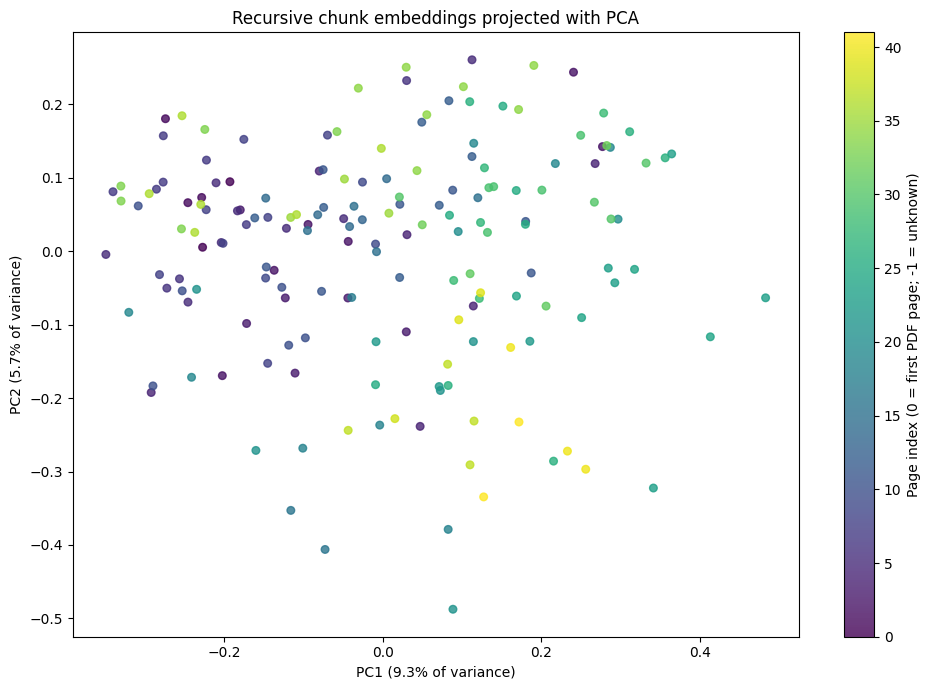

In [25]:
import matplotlib.pyplot as plt

# PCA with NumPy: center the vectors, then find the principal directions by SVD.
data = vectorstore_recursive._collection.get(include=["embeddings", "metadatas"])
X = np.asarray(data["embeddings"], dtype=float)

if X.ndim != 2 or min(X.shape) < 2:
    print("PCA needs at least two chunks and two embedding dimensions.")
else:
    centered = X - X.mean(axis=0)
    _, singular_values, directions = np.linalg.svd(centered, full_matrices=False)
    coordinates = centered @ directions[:2].T
    page_numbers = np.array([
        metadata.get("page", -1) if metadata else -1
        for metadata in data["metadatas"]
    ])
    total_variance = np.sum(singular_values ** 2)
    explained = (singular_values[:2] ** 2 / total_variance
                 if total_variance > 0 else np.zeros(2))

    fig, ax = plt.subplots(figsize=(10, 7))
    points = ax.scatter(coordinates[:, 0], coordinates[:, 1],
                        c=page_numbers, cmap="viridis", s=30, alpha=0.8)
    fig.colorbar(points, ax=ax, label="Page index (0 = first PDF page; -1 = unknown)")
    ax.set_xlabel(f"PC1 ({explained[0]:.1%} of variance)")
    ax.set_ylabel(f"PC2 ({explained[1]:.1%} of variance)")
    ax.set_title("Recursive chunk embeddings projected with PCA")
    fig.tight_layout()
    plt.show()


---
## Checkpoint — What you have built

```
  Your PDF
     │
     ▼
  PyPDFLoader  ──►  pages (Document list)       ✅
     │
     ├──► RecursiveCharacterTextSplitter  ──►  chunks_recursive   ✅
     │
     └──► SemanticChunker  ──►  chunks_semantic                   ✅
              │                    │
              ▼                    ▼
         ChromaDB              ChromaDB
       (rapport_recursive)   (rapport_semantic)                   ✅
              │                    │
              ▼                    ▼
         retriever_recursive   retriever_semantic                 ✅
              │
              ▼
         top-k chunks for any query                               ✅
```

### In Part 2, you will add:

```
  retriever  ──►  relevant chunks
                       │
                       ▼
                  LLM (qwen2.5:3b)
                       │
                       ▼
                  grounded answer
                       │
                       ▼
                  RAGAS evaluation
                  (faithfulness - context precision - answer relevancy)
```

**Before Part 2:**  
Make sure `chroma_db/` is in the same folder as the Part 2 notebook —
you will reload from disk without re-embedding.